**Q1**

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Original Text:
 Football is a popular sport played between two teams of 11 players each.
 The aim is to score goals by kicking the ball into the opponent’s net. Football improves teamwork, fitness, and discipline. 
 It is enjoyed by millions of people around the world.
.

Cleaned Text:
 football is a popular sport played between two teams of 11 players each
 the aim is to score goals by kicking the ball into the opponents net football improves teamwork fitness and discipline 
 it is enjoyed by millions of people around the world


Word Tokens:
 ['Football', 'is', 'a', 'popular', 'sport', 'played', 'between', 'two', 'teams', 'of', '11', 'players', 'each', '.', 'The', 'aim', 'is', 'to', 'score', 'goals', 'by', 'kicking', 'the', 'ball', 'into', 'the', 'opponent', '’', 's', 'net', '.', 'Football', 'improves', 'teamwork', ',', 'fitness', ',', 'and', 'discipline', '.', 'It', 'is', 'enjoyed', 'by', 'millions', 'of', 'people', 'around', 'the', 'world', '.', '.']

Sentence Tokens:
 ['Football i

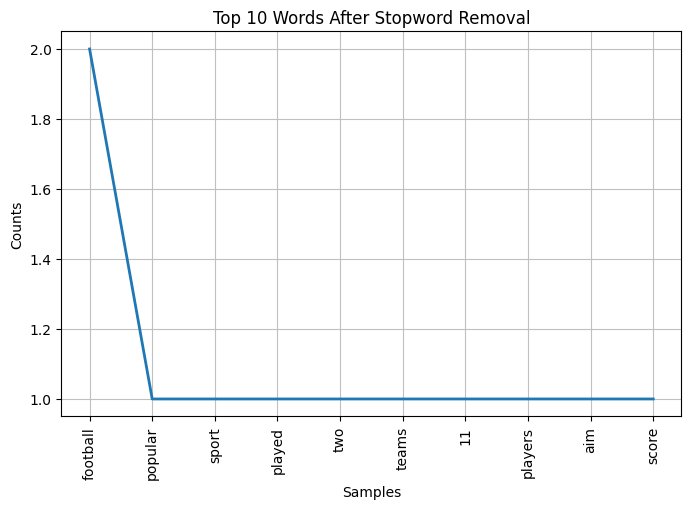

In [1]:

import re
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Football is a popular sport played between two teams of 11 players each.
 The aim is to score goals by kicking the ball into the opponent’s net. Football improves teamwork, fitness, and discipline.
 It is enjoyed by millions of people around the world.
."""

print("Original Text:\n", text)

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("\nCleaned Text:\n", clean_text)

words = word_tokenize(text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

split_words = clean_text.split()
nltk_words = word_tokenize(clean_text)

print("\nTokens using split():\n", split_words)
print("\nTokens using word_tokenize():\n", nltk_words)

print("\nAre both token lists identical?", split_words == nltk_words)


stop_words = set(stopwords.words('english'))
filtered_words = [word for word in nltk_words if word not in stop_words]

print("\nTokens after removing stopwords:\n", filtered_words)


freq_dist = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in freq_dist.most_common():
    print(word, ":", count)


plt.figure(figsize=(8, 5))
freq_dist.plot(10, title="Top 10 Words After Stopword Removal")
plt.show()



**Q2**

In [2]:

from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords
import re
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
words = re.findall(r'\b[A-Za-z]+\b', text.lower())

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

porter = PorterStemmer()
stemmed_words = [porter.stem(word) for word in filtered_words]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]

print("After Removing Stopwords:")
print(filtered_words)

print("\nStemmed Words:")
print(stemmed_words)

print("\nLemmatized Words:")
print(lemmatized_words)

print("\nComparison:")
for word, stem, lemma in zip(filtered_words, stemmed_words, lemmatized_words):
    print(word, "-> Stem:", stem, "| Lemma:", lemma)



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


After Removing Stopwords:
['football', 'popular', 'sport', 'played', 'two', 'teams', 'players', 'aim', 'score', 'goals', 'kicking', 'ball', 'opponent', 'net', 'football', 'improves', 'teamwork', 'fitness', 'discipline', 'enjoyed', 'millions', 'people', 'around', 'world']

Stemmed Words:
['footbal', 'popular', 'sport', 'play', 'two', 'team', 'player', 'aim', 'score', 'goal', 'kick', 'ball', 'oppon', 'net', 'footbal', 'improv', 'teamwork', 'fit', 'disciplin', 'enjoy', 'million', 'peopl', 'around', 'world']

Lemmatized Words:
['football', 'popular', 'sport', 'played', 'two', 'team', 'player', 'aim', 'score', 'goal', 'kicking', 'ball', 'opponent', 'net', 'football', 'improves', 'teamwork', 'fitness', 'discipline', 'enjoyed', 'million', 'people', 'around', 'world']

Comparison:
football -> Stem: footbal | Lemma: football
popular -> Stem: popular | Lemma: popular
sport -> Stem: sport | Lemma: sport
played -> Stem: play | Lemma: played
two -> Stem: two | Lemma: two
teams -> Stem: team | Lemma

**Q3**

In [5]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd
import numpy as np

texts = [
    "Cricket is a popular sport played between two teams of 11 players each",
     "Cricket matches can be played in Test, One Day International, and T20 formats",
     "The aim of cricket is to score more runs than the opposing team"
]

cv = CountVectorizer()
bow = cv.fit_transform(texts)

bow_df = pd.DataFrame(
    bow.toarray(),
    columns=cv.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("Bag of Words Representation:")
display(bow_df)

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("\nTF-IDF Scores:")
display(tfidf_df.round(3))

terms = tfidf.get_feature_names_out()

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = np.argsort(scores)[-3:][::-1]

    print(f"\nText {i + 1}: {text}")
    print("Top 3 keywords:")

    for idx in top_indices:
        print(f"{terms[idx]}: {scores[idx]:.3f}")



Bag of Words Representation:


,11,aim,and,be,between,can,cricket,day,each,formats,...,score,sport,t20,team,teams,test,than,the,to,two
Text 1,1,0,0,0,1,0,1,0,1,0,...,0,1,0,0,1,0,0,0,0,1
Text 2,0,0,1,1,0,1,1,1,0,1,...,0,0,1,0,0,1,0,0,0,0
Text 3,0,1,0,0,0,0,1,0,0,0,...,1,0,0,1,0,0,1,2,1,0



TF-IDF Scores:


,11,aim,and,be,between,can,cricket,day,each,formats,...,score,sport,t20,team,teams,test,than,the,to,two
Text 1,0.315,0.000,0.00,0.00,0.315,0.00,0.186,0.00,0.315,0.00,...,0.000,0.315,0.00,0.000,0.315,0.00,0.000,0.000,0.000,0.315
Text 2,0.000,0.000,0.29,0.29,0.000,0.29,0.171,0.29,0.000,0.29,...,0.000,0.000,0.29,0.000,0.000,0.29,0.000,0.000,0.000,0.000
Text 3,0.000,0.272,0.00,0.00,0.000,0.00,0.161,0.00,0.000,0.00,...,0.272,0.000,0.00,0.272,0.000,0.00,0.272,0.544,0.272,0.000



Text 1: Cricket is a popular sport played between two teams of 11 players each
Top 3 keywords:
two: 0.315
teams: 0.315
popular: 0.315

Text 2: Cricket matches can be played in Test, One Day International, and T20 formats
Top 3 keywords:
t20: 0.290
test: 0.290
one: 0.290

Text 3: The aim of cricket is to score more runs than the opposing team
Top 3 keywords:
the: 0.544
to: 0.272
than: 0.272


**Q4**

In [7]:

import re
import nltk
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Call of Duty: Warfare is a first-person shooter game.
Players complete missions and fight enemies using various weapons.
The game features intense combat and multiplayer modes.
Players can work together with teammates to achieve objectives.
Call of Duty is popular for its action-packed gameplay."""

text2 = """Ghost of Tsushima is an action-adventure game set in Japan.
Players control a samurai named Jin Sakai.
The game focuses on sword fighting, stealth, and exploration.
Players explore an open world inspired by feudal Japan.
The story follows Jin as he protects Tsushima Island from Mongol invaders."""

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    tokens = nltk.word_tokenize(text)
    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Text 1 Tokens:", tokens1)
print("Text 2 Tokens:", tokens2)

set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1 & set2) / len(set1 | set2)

print("\nJaccard Similarity:", round(jaccard, 4))

texts = [text1, text2]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("Cosine Similarity:", round(cosine, 4))

print("\nAnalysis:")
if cosine > jaccard:
    print("Cosine similarity gives a higher similarity score because it considers TF-IDF word weights.")
elif jaccard > cosine:
    print("Jaccard similarity gives a higher score based on the proportion of shared unique words.")
else:
    print("Both metrics give the same similarity score.")



Text 1 Tokens: ['call', 'of', 'duty', 'warfare', 'is', 'a', 'firstperson', 'shooter', 'game', 'players', 'complete', 'missions', 'and', 'fight', 'enemies', 'using', 'various', 'weapons', 'the', 'game', 'features', 'intense', 'combat', 'and', 'multiplayer', 'modes', 'players', 'can', 'work', 'together', 'with', 'teammates', 'to', 'achieve', 'objectives', 'call', 'of', 'duty', 'is', 'popular', 'for', 'its', 'actionpacked', 'gameplay']
Text 2 Tokens: ['ghost', 'of', 'tsushima', 'is', 'an', 'actionadventure', 'game', 'set', 'in', 'japan', 'players', 'control', 'a', 'samurai', 'named', 'jin', 'sakai', 'the', 'game', 'focuses', 'on', 'sword', 'fighting', 'stealth', 'and', 'exploration', 'players', 'explore', 'an', 'open', 'world', 'inspired', 'by', 'feudal', 'japan', 'the', 'story', 'follows', 'jin', 'as', 'he', 'protects', 'tsushima', 'island', 'from', 'mongol', 'invaders']

Jaccard Similarity: 0.1
Cosine Similarity: 0.1702

Analysis:
Cosine similarity gives a higher similarity score becaus

**Jaccard Similarity:** It measures the overlap of unique words between two texts without considering their frequency. The score is low because the texts share very few words, such as "data".

**Cosine Similarity:** It compares the TF-IDF vectors of both texts and considers the importance of words. Its score is also low because the texts discuss different technologies.

**Conclusion:** Cosine similarity with TF-IDF provides better insight in this case because it considers word importance. Jaccard similarity is useful for checking vocabulary overlap, while cosine similarity is more suitable for comparing text similarity using weighted features.


**Q5**

Review: Call of Duty: Modern Warfare has amazing graphics, intense combat and exciting multiplayer battles.
Polarity: 0.325
Subjectivity: 0.75
Sentiment: Positive

Review: The missions are fun, but some multiplayer matches feel unbalanced and frustrating.
Polarity: -0.05
Subjectivity: 0.55
Sentiment: Neutral

Review: Ghost of Tsushima has a beautiful open world with stunning landscapes and impressive visuals.
Polarity: 0.588
Subjectivity: 0.875
Sentiment: Positive

Review: I love the sword combat in Ghost of Tsushima, it feels smooth, realistic and satisfying.
Polarity: 0.392
Subjectivity: 0.608
Sentiment: Positive

Review: Call of Duty has exciting action, but the frequent updates and large downloads can be annoying.
Polarity: -0.017
Subjectivity: 0.506
Sentiment: Neutral

Review: Ghost of Tsushima has an emotional story, memorable characters and excellent voice acting.
Polarity: 0.375
Subjectivity: 0.662
Sentiment: Positive

Review: The stealth missions in Ghost of Tsushima are enjoy

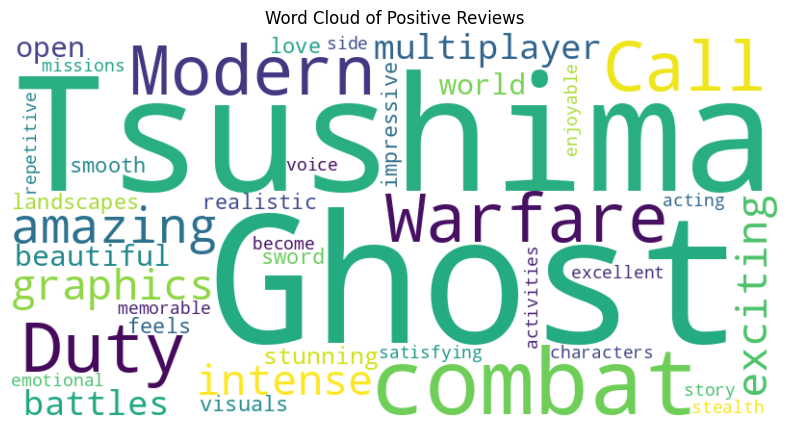

In [11]:
from textblob import TextBlob
import matplotlib.pyplot as plt
from wordcloud import WordCloud

reviews = [
    "Call of Duty: Modern Warfare has amazing graphics, intense combat and exciting multiplayer battles.",
    "The missions are fun, but some multiplayer matches feel unbalanced and frustrating.",
    "Ghost of Tsushima has a beautiful open world with stunning landscapes and impressive visuals.",
    "I love the sword combat in Ghost of Tsushima, it feels smooth, realistic and satisfying.",
    "Call of Duty has exciting action, but the frequent updates and large downloads can be annoying.",
    "Ghost of Tsushima has an emotional story, memorable characters and excellent voice acting.",
    "The stealth missions in Ghost of Tsushima are enjoyable, but some side activities become repetitive."
]



positive_reviews = []

for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)
    print()

if positive_reviews:
    text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()


**Q6**

In [12]:

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

text = """
Technology is changing the world rapidly.
Artificial intelligence helps people solve complex problems.
Machine learning allows computers to learn from data.
Python is a popular programming language.
Students use technology to develop innovative applications.
Computer science provides many career opportunities.
Learning new skills helps students build their future.
Modern technology improves communication and education.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
sequences = []

for line in text.strip().split('\n'):
    tokens = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(tokens)):
        sequences.append(tokens[:i + 1])

max_len = max(len(seq) for seq in sequences)

sequences = np.array([
    np.pad(seq, (max_len - len(seq), 0))
    for seq in sequences
])

X = sequences[:, :-1]
y = to_categorical(sequences[:, -1], num_classes=total_words)

model = Sequential([
    Embedding(total_words, 32, input_length=max_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=200, verbose=0)


def generate_text(seed, next_words=8):
    for _ in range(next_words):
        tokens = tokenizer.texts_to_sequences([seed])[0]
        tokens = tokens[-(max_len - 1):]

        padded = np.pad(
            tokens,
            (max(0, max_len - 1 - len(tokens)), 0)
        )

        prediction = model.predict(
            np.array([padded]), verbose=0
        )

        next_index = np.argmax(prediction)
        next_word = tokenizer.index_word.get(next_index, '')

        if not next_word:
            break

        seed += ' ' + next_word

    return seed


print(generate_text("technology", 8))
print(generate_text("machine learning", 8))
print(generate_text("students", 8))




/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


technology is changing the world rapidly rapidly future language
machine learning allows computers to learn from data data data
students use technology to develop innovative applications applications future
